# FIFA World Cup 2026 — Linear Regression (Objective 2)
## Part A: data wrangling — building the 104-row and 208-row datasets

**Raw inputs**
* `Players.xlsx` — one row per player per match for all 104 matches (FBref match reports, collected in Assessment 2).
* `team_info.csv` — static pre-tournament facts per team: FIFA/Coca-Cola Men's World Ranking of 11 June 2026
  (published before the opening match), number of World Cup appearances before 2026, and host-nation flag.

**Rule applied to every explanatory variable:** it must be known before kick-off of the match it describes.
In-tournament "form" variables therefore use **only matches the team played earlier** in the tournament.

In [1]:
import numpy as np
import pandas as pd

p = pd.read_excel("Players.xlsx")
for c in ["game", "team", "game_id"]:
    p[c] = p[c].ffill()                     # labels only appear on the first row of each block
p["match_date"] = pd.to_datetime(p["game"].str[:10])
p["age_years"] = p["age"].str.split("-").str[0].astype(float) + p["age"].str.split("-").str[1].astype(float) / 365.25
print(p.shape, "matches:", p.game_id.nunique(), "teams:", p.team.nunique())

info = pd.read_csv("team_info.csv")

(3288, 29) matches: 104 teams: 48


### Step 1 — team-match table (208 rows)
Goals for a team = goals by its own players (penalties included) + own goals conceded by the opponent.
Penalty-shoot-out kicks are not goals and are excluded, so a shoot-out match counts as a draw.

In [2]:
tm = p.groupby(["game_id", "game", "match_date", "team"], as_index=False).agg(
    gls=("Performance_Gls", "sum"), og=("Performance_OG", "sum"),
    shots=("Performance_Sh", "sum"), sot=("Performance_SoT", "sum"),
    yellow=("Performance_CrdY", "sum"), red=("Performance_CrdR", "sum"))

opp = tm[["game_id", "team", "og", "gls", "sot"]].rename(columns={"team": "opponent", "og": "opp_og", "gls": "opp_gls", "sot": "opp_sot"})
tm = tm.merge(opp, on="game_id")
tm = tm[tm.team != tm.opponent].copy()
tm["goals_for"] = tm.gls + tm.opp_og
tm["goals_against"] = tm.opp_gls + tm.og
tm["points"] = np.select([tm.goals_for > tm.goals_against, tm.goals_for == tm.goals_against], [3, 1], 0)
assert len(tm) == 208

# Team A = first team named by FIFA in the fixture ("YYYY-MM-DD TeamA-TeamB")
fixture = (tm.game.str[11:].str.replace("USA-", "United States-", regex=False)
           .str.replace("Bosnia–Herz", "Bosnia and Herzegovina", regex=False))   # FBref short names
tm["is_team_a"] = [f.startswith(t + "-") for f, t in zip(fixture, tm.team)]
assert tm.groupby("game_id").is_team_a.sum().eq(1).all()

### Step 2 — pre-match variables
* **Rest days**: days since the team's previous match (capped at 7; the first match is set to 7 = fully rested).
* **Knockout**: the team's 4th or later match. Every team plays exactly 3 group matches.
* **Form variables** (goals for/against, goal difference, points, shots on target per game) use only
  earlier matches. To handle matchday 1 (no history) and to stop one result dominating, each average is
  shrunk towards a pre-tournament prior with weight of one match:
  `form = (sum of earlier values + prior) / (earlier matches + 1)`.
  The goals prior comes from the 2022 World Cup (172 goals in 64 matches = 1.34 goals per team per match),
  so no 2026 information leaks in. In a given match both teams have always played the same number of
  earlier matches, so in the Team A − Team B differences of model 2.1 the prior cancels out exactly
  (matchday-1 differences are 0 = "no evidence either way"); the points/SoT priors are therefore placeholders.
* **Squad age**: mean age of the players the team used (all registered before the tournament).

In [3]:
tm = tm.sort_values(["team", "match_date"]).reset_index(drop=True)
g = tm.groupby("team")
tm["match_no"] = g.cumcount() + 1
tm["knockout"] = (tm.match_no > 3).astype(int)
tm["rest_days"] = g.match_date.diff().dt.days.fillna(7).clip(upper=7)

PRIOR = {"goals_for": 1.34, "goals_against": 1.34, "points": 1.36, "sot": 4.0}
tm["gd"] = tm.goals_for - tm.goals_against
PRIOR["gd"] = 0.0
for col, prior in PRIOR.items():
    earlier_sum = g[col].cumsum() - tm[col]            # sum over earlier matches only
    tm[f"form_{col}"] = (earlier_sum + prior) / (tm.match_no - 1 + 1)

squad_age = p.groupby(["team", "player"]).age_years.min().groupby("team").mean().rename("squad_age")
tm = tm.merge(squad_age, on="team").merge(info, on="team")
tm["log_rank"] = np.log(tm.fifa_rank_jun2026)

### Step 3 — attach the opponent's pre-match values

In [4]:
opp_cols = ["log_rank", "host", "rest_days", "form_goals_for", "form_goals_against", "form_gd",
            "form_points", "form_sot", "squad_age", "wc_appearances_before_2026"]
o = tm[["game_id", "team"] + opp_cols].rename(columns={"team": "opponent", **{c: "opp_" + c for c in opp_cols}})
tm = tm.merge(o, on=["game_id", "opponent"])
assert len(tm) == 208

### Step 4 — Dataset 2.1: one row per match (104 rows), Team A minus Team B
Rank enters as log(rank of B) − log(rank of A), so a positive value means Team A is the stronger side
and the log reflects that the gap between 1st and 10th matters more than between 50th and 60th.

In [5]:
a = tm[tm.is_team_a].copy()
match = pd.DataFrame({
    "match_id": a.game_id, "match": a.game, "date": a.match_date.dt.date,
    "team_a": a.team, "team_b": a.opponent,
    "rank_strength_diff": a.opp_log_rank - a.log_rank,
    "host_diff": a.host - a.opp_host,
    "rest_diff": a.rest_days - a.opp_rest_days,
    "knockout": a.knockout,
    "form_gd_diff": a.form_gd - a.opp_form_gd,
    "form_points_diff": a.form_points - a.opp_form_points,
    "form_sot_diff": a.form_sot - a.opp_form_sot,
    "wc_experience_diff": a.wc_appearances_before_2026 - a.opp_wc_appearances_before_2026,
    "goal_diff": a.goals_for - a.goals_against,
}).sort_values("date").reset_index(drop=True)
assert len(match) == 104
match.to_csv("dataset_2_1_match_goal_difference.csv", index=False)

### Step 5 — Dataset 2.2: one row per team per match (208 rows)

In [6]:
team = pd.DataFrame({
    "match_id": tm.game_id, "match": tm.game, "date": tm.match_date.dt.date,
    "team": tm.team, "opponent": tm.opponent,
    "own_rank_strength": -tm.log_rank,          # higher = stronger
    "host": tm.host,
    "rest_days": tm.rest_days,
    "knockout": tm.knockout,
    "opp_rank_strength": -tm.opp_log_rank,
    "form_goals_for": tm.form_goals_for,
    "opp_form_goals_against": tm.opp_form_goals_against,
    "squad_age": tm.squad_age,
    "goals": tm.goals_for,
}).sort_values(["date", "match_id", "team"]).reset_index(drop=True)
assert len(team) == 208
team.to_csv("dataset_2_2_team_goals.csv", index=False)

print(match.describe().T.round(2))
print(team.describe().T.round(2))

                    count  mean   std    min   25%   50%    75%   max
rank_strength_diff  104.0  0.38  1.58  -4.14 -0.78  0.43   1.42   4.2
host_diff           104.0  0.07  0.38  -1.00  0.00  0.00   0.00   1.0
rest_diff           104.0  0.10  0.47  -1.00  0.00  0.00   0.00   2.0
knockout            104.0  0.31  0.46   0.00  0.00  0.00   1.00   1.0
form_gd_diff        104.0  0.14  1.16  -4.00  0.00  0.00   0.75   2.5
form_points_diff    104.0  0.05  0.65  -2.00  0.00  0.00   0.33   1.5
form_sot_diff       104.0  0.34  1.65  -5.20 -0.50  0.00   1.04   4.5
wc_experience_diff  104.0  2.74  8.68 -18.00 -3.00  2.00  10.00  21.0
goal_diff           104.0  0.48  2.02  -4.00 -1.00  0.00   2.00   6.0
                        count   mean   std    min    25%    50%    75%    max
own_rank_strength       208.0  -2.84  1.14  -4.44  -3.71  -3.11  -2.17  -0.00
host                    208.0   0.07  0.26   0.00   0.00   0.00   0.00   1.00
rest_days               208.0   5.67  1.09   3.00   5.00   6.00   

## Part B: linear regression models
Both models use ordinary least squares (statsmodels for inference, scikit-learn for out-of-sample evaluation).

**Evaluation design** (identical for both models, so they can be compared):
1. Fit on all rows to read coefficients, p-values, R² and adjusted R².
2. Hold-out test: 80/20 random split (seed 42), fit on 80 %, score on the unseen 20 %.
3. Repeated 5-fold cross-validation (10 repeats = 50 fits), so results don't hinge on one lucky split.
4. Every score is compared with a **baseline that always predicts the training mean** — a model is only
   useful if it beats this.
5. Diagnostics: variance inflation factors (multicollinearity), residual plots, Q-Q plot.

In [7]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, RepeatedKFold, cross_validate
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

warnings.filterwarnings("ignore")
SEED = 42
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

d1 = pd.read_csv("dataset_2_1_match_goal_difference.csv")
d2 = pd.read_csv("dataset_2_2_team_goals.csv")
X1_COLS = ["rank_strength_diff", "host_diff", "rest_diff", "knockout",
           "form_gd_diff", "form_points_diff", "form_sot_diff", "wc_experience_diff"]
X2_COLS = ["own_rank_strength", "host", "rest_days", "knockout",
           "opp_rank_strength", "form_goals_for", "opp_form_goals_against", "squad_age"]
print("2.1:", d1.shape, " 2.2:", d2.shape)
print("explanatory variables:", len(X1_COLS), len(X2_COLS))
print("shared concepts: FIFA ranking strength, host nation, rest days, knockout stage  (4 = maximum allowed)")

2.1: (104, 14)  2.2: (208, 14)
explanatory variables: 8 8
shared concepts: FIFA ranking strength, host nation, rest days, knockout stage  (4 = maximum allowed)


In [8]:
def evaluate(df, xcols, ycol, name):
    X, y = df[xcols], df[ycol]
    out = {"model": name}

    # 1. full-data OLS for inference
    ols = sm.OLS(y, sm.add_constant(X)).fit()
    out["ols"] = ols
    out["R2_full"], out["adjR2_full"] = ols.rsquared, ols.rsquared_adj

    # 2. hold-out test
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=SEED)
    lr = LinearRegression().fit(Xtr, ytr)
    pred = lr.predict(Xte)
    base = np.full(len(yte), ytr.mean())
    out.update(test_R2=r2_score(yte, pred), test_RMSE=mean_squared_error(yte, pred) ** 0.5,
               test_MAE=mean_absolute_error(yte, pred), base_RMSE=mean_squared_error(yte, base) ** 0.5,
               base_MAE=mean_absolute_error(yte, base), n_train=len(ytr), n_test=len(yte))

    # 3. repeated 5-fold CV (model vs mean baseline on identical folds)
    rkf = RepeatedKFold(n_splits=5, n_repeats=10, random_state=SEED)
    cv = cross_validate(LinearRegression(), X, y, cv=rkf,
                        scoring=["r2", "neg_root_mean_squared_error", "neg_mean_absolute_error"])
    base_rmse = [np.sqrt(np.mean((y.iloc[te] - y.iloc[tr].mean()) ** 2)) for tr, te in rkf.split(X)]
    out.update(cv_R2=cv["test_r2"].mean(), cv_R2_sd=cv["test_r2"].std(),
               cv_RMSE=-cv["test_neg_root_mean_squared_error"].mean(),
               cv_MAE=-cv["test_neg_mean_absolute_error"].mean(), cv_base_RMSE=np.mean(base_rmse))

    # 5. diagnostics
    Xc = sm.add_constant(X)
    out["vif"] = pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])], index=xcols)
    out["bp_p"] = het_breuschpagan(ols.resid, Xc)[1]
    out["shapiro_p"] = stats.shapiro(ols.resid)[1]
    out["fitted"], out["resid"], out["y"] = ols.fittedvalues, ols.resid, y
    return out


def coef_table(res, X):
    ols = res["ols"]
    t = pd.DataFrame({"coef": ols.params, "std_err": ols.bse, "t": ols.tvalues, "p": ols.pvalues})
    sd = X.std()
    t["std_coef"] = (ols.params.drop("const") * sd / res["y"].std()).reindex(t.index)   # standardised beta
    return t.round(3)


def summary_row(r):
    keys = ["R2_full", "adjR2_full", "test_R2", "test_RMSE", "base_RMSE", "test_MAE", "base_MAE",
            "cv_R2", "cv_R2_sd", "cv_RMSE", "cv_base_RMSE", "cv_MAE", "bp_p", "shapiro_p"]
    return pd.Series({k: r[k] for k in keys}, name=r["model"]).round(3)


def diagnostics_plot(res, title, fname):
    fig, ax = plt.subplots(1, 3, figsize=(10, 2.9))
    ax[0].scatter(res["fitted"], res["y"], s=12, alpha=.6)
    lim = [min(res["fitted"].min(), res["y"].min()) - .5, max(res["fitted"].max(), res["y"].max()) + .5]
    ax[0].plot(lim, lim, "r--", lw=1); ax[0].set(xlabel="Predicted", ylabel="Actual", title="Actual vs predicted")
    ax[1].scatter(res["fitted"], res["resid"], s=12, alpha=.6); ax[1].axhline(0, color="r", ls="--", lw=1)
    ax[1].set(xlabel="Predicted", ylabel="Residual", title="Residuals vs predicted")
    stats.probplot(res["resid"], plot=ax[2]); ax[2].set_title("Normal Q-Q of residuals")
    ax[2].get_lines()[0].set_markersize(3)
    fig.suptitle(title, fontsize=10, y=1.02); fig.tight_layout(); fig.savefig(fname, bbox_inches="tight", dpi=200)
    plt.show()

### Linear Regression 2.1 — goal difference (Team A − Team B), 104 matches
**Explanatory variables (all known before kick-off):**

| Variable | Meaning |
|---|---|
| `rank_strength_diff` | log(FIFA rank B) − log(FIFA rank A), ranking of 11 June 2026 |
| `host_diff` | +1 if A is a host nation, −1 if B is, 0 otherwise |
| `rest_diff` | rest days of A − rest days of B |
| `knockout` | 1 if knockout match |
| `form_gd_diff` | difference in goal difference per game in earlier 2026 matches |
| `form_points_diff` | difference in points per game in earlier 2026 matches |
| `form_sot_diff` | difference in shots on target per game in earlier 2026 matches |
| `wc_experience_diff` | difference in World Cup appearances before 2026 |

In [9]:
print(d1[X1_COLS + ["goal_diff"]].describe().T.round(2))
print("\nCorrelation with goal_diff:")
print(d1[X1_COLS].corrwith(d1.goal_diff).round(3).sort_values(ascending=False))

                    count  mean   std    min   25%   50%    75%   max
rank_strength_diff  104.0  0.38  1.58  -4.14 -0.78  0.43   1.42   4.2
host_diff           104.0  0.07  0.38  -1.00  0.00  0.00   0.00   1.0
rest_diff           104.0  0.10  0.47  -1.00  0.00  0.00   0.00   2.0
knockout            104.0  0.31  0.46   0.00  0.00  0.00   1.00   1.0
form_gd_diff        104.0  0.14  1.16  -4.00  0.00  0.00   0.75   2.5
form_points_diff    104.0  0.05  0.65  -2.00  0.00  0.00   0.33   1.5
form_sot_diff       104.0  0.34  1.65  -5.20 -0.50  0.00   1.04   4.5
wc_experience_diff  104.0  2.74  8.68 -18.00 -3.00  2.00  10.00  21.0
goal_diff           104.0  0.48  2.02  -4.00 -1.00  0.00   2.00   6.0

Correlation with goal_diff:
rank_strength_diff    0.629
wc_experience_diff    0.533
form_gd_diff          0.328
form_points_diff      0.310
form_sot_diff         0.241
host_diff             0.123
rest_diff            -0.049
knockout             -0.087
dtype: float64


In [10]:
r1 = evaluate(d1, X1_COLS, "goal_diff", "LR 2.1 goal difference")
print(r1["ols"].summary())
ct1 = coef_table(r1, d1[X1_COLS]); print(ct1)
print("\nVIF:\n", r1["vif"].round(2))

                            OLS Regression Results                            
Dep. Variable:              goal_diff   R-squared:                       0.445
Model:                            OLS   Adj. R-squared:                  0.398
Method:                 Least Squares   F-statistic:                     9.516
Date:                Sun, 11 Oct 2026   Prob (F-statistic):           1.39e-09
Time:                        00:20:37   Log-Likelihood:                -189.79
No. Observations:                 104   AIC:                             397.6
Df Residuals:                      95   BIC:                             421.4
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  0.3306      0

In [11]:
# Result-direction check: does the sign of the prediction match win / loss? (draws: |pred| < 0.5)
pred_res = np.select([r1["fitted"] > .5, r1["fitted"] < -.5], ["A win", "B win"], "Draw")
act_res = np.select([d1.goal_diff > 0, d1.goal_diff < 0], ["A win", "B win"], "Draw")
r1["outcome_acc"] = (pred_res == act_res).mean()
print("In-sample W/D/L accuracy:", round(r1["outcome_acc"], 3))
print(pd.crosstab(pd.Series(act_res, name="actual"), pd.Series(pred_res, name="predicted")))

In-sample W/D/L accuracy: 0.615
predicted  A win  B win  Draw
actual                       
A win         36      3    11
B win          1     22     7
Draw          14      4     6


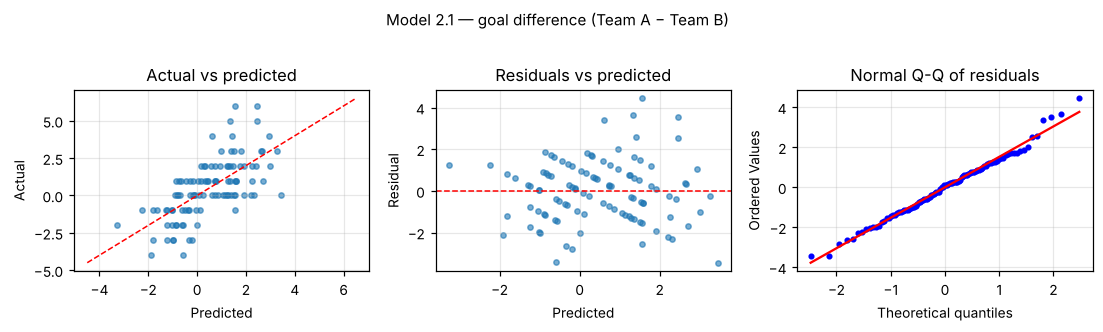

In [12]:
diagnostics_plot(r1, "Model 2.1 — goal difference (Team A − Team B)", "fig_2_1_diagnostics.png")

### Linear Regression 2.2 — goals scored by a team, 208 team-matches

| Variable | Meaning | Shared with 2.1? |
|---|---|---|
| `own_rank_strength` | −log(team's FIFA rank) | yes (ranking) |
| `host` | team is a host nation | yes |
| `rest_days` | team's days since previous match | yes |
| `knockout` | knockout match | yes |
| `opp_rank_strength` | −log(opponent's FIFA rank) | no |
| `form_goals_for` | team's goals scored per game in earlier 2026 matches | no |
| `opp_form_goals_against` | opponent's goals conceded per game in earlier 2026 matches | no |
| `squad_age` | mean age of the team's squad | no |

In [13]:
print(d2[X2_COLS + ["goals"]].describe().T.round(2))
print("\nCorrelation with goals:")
print(d2[X2_COLS].corrwith(d2.goals).round(3).sort_values(ascending=False))

                        count   mean   std    min    25%    50%    75%    max
own_rank_strength       208.0  -2.84  1.14  -4.44  -3.71  -3.11  -2.17  -0.00
host                    208.0   0.07  0.26   0.00   0.00   0.00   0.00   1.00
rest_days               208.0   5.67  1.09   3.00   5.00   6.00   7.00   7.00
knockout                208.0   0.31  0.46   0.00   0.00   0.00   1.00   1.00
opp_rank_strength       208.0  -2.84  1.14  -4.44  -3.71  -3.11  -2.17  -0.00
form_goals_for          208.0   1.56  0.62   0.45   1.17   1.34   1.87   4.17
opp_form_goals_against  208.0   1.28  0.59   0.22   0.87   1.17   1.34   4.17
squad_age               208.0  27.90  1.11  25.85  26.96  27.86  28.59  30.96
goals                   208.0   1.48  1.39   0.00   0.00   1.00   2.00   7.00

Correlation with goals:
own_rank_strength         0.369
opp_form_goals_against    0.203
host                      0.104
form_goals_for            0.097
knockout                 -0.013
rest_days                -0.052
squ

In [14]:
r2 = evaluate(d2, X2_COLS, "goals", "LR 2.2 team goals")
print(r2["ols"].summary())
ct2 = coef_table(r2, d2[X2_COLS]); print(ct2)
print("\nVIF:\n", r2["vif"].round(2))
print("\nNote: the two rows of one match share the same game, so rows are not fully independent;"
      "\ncluster-robust standard errors by match are reported as a check:")
rob = sm.OLS(d2.goals, sm.add_constant(d2[X2_COLS])).fit(cov_type="cluster",
                                                         cov_kwds={"groups": pd.factorize(d2.match_id)[0]})
r2["cluster_p"] = rob.pvalues
print(rob.pvalues.round(3))

                            OLS Regression Results                            
Dep. Variable:                  goals   R-squared:                       0.266
Model:                            OLS   Adj. R-squared:                  0.236
Method:                 Least Squares   F-statistic:                     9.014
Date:                Sun, 11 Oct 2026   Prob (F-statistic):           1.55e-10
Time:                        00:20:38   Log-Likelihood:                -331.49
No. Observations:                 208   AIC:                             681.0
Df Residuals:                     199   BIC:                             711.0
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                      4

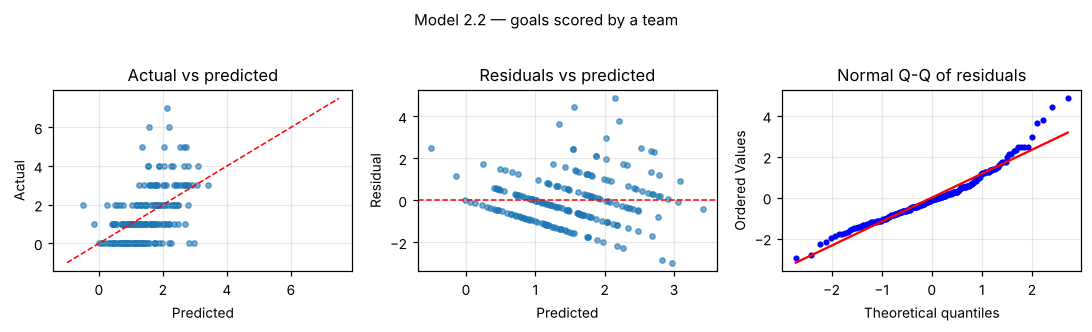

In [15]:
diagnostics_plot(r2, "Model 2.2 — goals scored by a team", "fig_2_2_diagnostics.png")

### Comparison and coefficient figure

              LR 2.1 goal difference  LR 2.2 team goals
R2_full                        0.445              0.266
adjR2_full                     0.398              0.236
test_R2                        0.374              0.249
test_RMSE                      1.869              1.289
base_RMSE                      2.391              1.511
test_MAE                       1.599              0.966
base_MAE                       1.984              1.180
cv_R2                          0.246              0.175
cv_R2_sd                       0.255              0.113
cv_RMSE                        1.639              1.241
cv_base_RMSE                   2.008              1.386
cv_MAE                         1.313              0.932
bp_p                           0.180              0.186
shapiro_p                      0.650              0.000


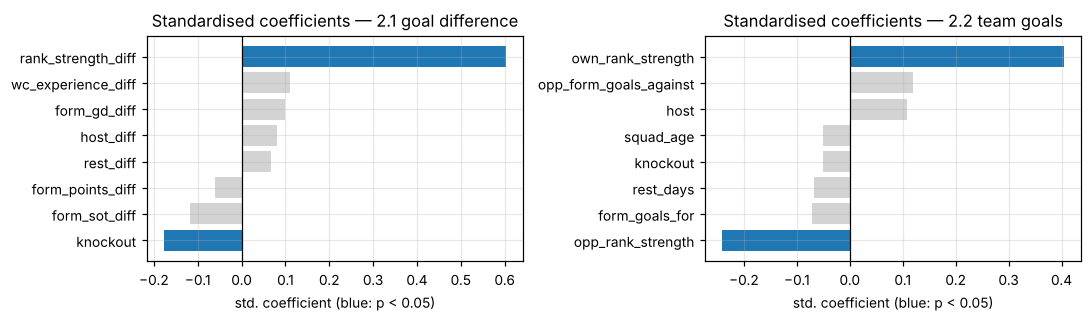

In [16]:
summary = pd.concat([summary_row(r1), summary_row(r2)], axis=1)
print(summary)
summary.to_csv("model_summary.csv")
ct1.to_csv("coefficients_2_1.csv"); ct2.to_csv("coefficients_2_2.csv")

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
for a, ct, title in [(ax[0], ct1, "2.1 goal difference"), (ax[1], ct2, "2.2 team goals")]:
    s = ct.drop("const").sort_values("std_coef")
    colors = ["tab:blue" if p < .05 else "lightgray" for p in s.p]
    a.barh(s.index, s.std_coef, color=colors); a.axvline(0, color="k", lw=.8)
    a.set(title=f"Standardised coefficients — {title}", xlabel="std. coefficient (blue: p < 0.05)")
fig.tight_layout(); fig.savefig("fig_coefficients.png", bbox_inches="tight", dpi=200); plt.show()

### Robustness: is the extra complexity worth it?
Compare each 8-variable model with a 1-variable model (ranking only) under the same repeated CV.

In [17]:
for df, cols, y, one in [(d1, X1_COLS, "goal_diff", ["rank_strength_diff"]),
                         (d2, X2_COLS, "goals", ["own_rank_strength", "opp_rank_strength"])]:
    rkf = RepeatedKFold(n_splits=5, n_repeats=10, random_state=SEED)
    for label, c in [("all 8", cols), ("ranking only", one)]:
        s = cross_validate(LinearRegression(), df[c], df[y], cv=rkf, scoring="neg_root_mean_squared_error")
        print(f"{y:10s} {label:13s} CV RMSE = {-s['test_score'].mean():.3f}")

goal_diff  all 8         CV RMSE = 1.639
goal_diff  ranking only  CV RMSE = 1.590


goals      all 8         CV RMSE = 1.241
goals      ranking only  CV RMSE = 1.221
